In [1]:
import pandas as pd
from pathlib import Path

# Locating the engineered dataset relative to this notebook
data_path = Path("../data/processed/credit_default_engineered.csv")

# Loading the saved dataset for model development
model_df = pd.read_csv(data_path)

# Checking the dataset dimensions and available columns
print("Shape:", model_df.shape)
print("\nColumns:")
print(model_df.columns.tolist())

Shape: (29965, 29)

Columns:
['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'Y', 'average_bill_amount', 'average_payment_amount', 'maximum_payment_delay', 'number_of_months_with_delay', 'latest_bill_to_credit_limit_ratio']


In [2]:
# Separating the outcome from the information used to predict it
target_col = "Y"

# Excluding the target and demographic variables from the initial model
excluded_cols = ["Y", "SEX", "EDUCATION", "MARRIAGE", "AGE"]

# Defining the initial predictor set
feature_cols = [col for col in model_df.columns if col not in excluded_cols]

print("Number of predictors:", len(feature_cols))
print("Predictors:", feature_cols)
print("Target:", target_col)

Number of predictors: 24
Predictors: ['LIMIT_BAL', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'average_bill_amount', 'average_payment_amount', 'maximum_payment_delay', 'number_of_months_with_delay', 'latest_bill_to_credit_limit_ratio']
Target: Y


In [3]:

from sklearn.model_selection import train_test_split

# Separating predictor variables from the outcome
X = model_df[feature_cols]
y = model_df[target_col]

# Creating an 80/20 split while preserving the default rate
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Verifying split sizes and target proportions
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nTraining default rate:", round(y_train.mean(), 4))
print("Test default rate:", round(y_test.mean(), 4))

Training set: (23972, 24)
Test set: (5993, 24)

Training default rate: 0.2213
Test default rate: 0.2213


In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Training a baseline that always predicts the majority class
dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train, y_train)

# Evaluating baseline predictions on the held-out test set
dummy_pred = dummy_model.predict(X_test)
dummy_prob = dummy_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, dummy_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, dummy_prob), 4))

              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4667
           1       0.00      0.00      0.00      1326

    accuracy                           0.78      5993
   macro avg       0.39      0.50      0.44      5993
weighted avg       0.61      0.78      0.68      5993

ROC-AUC: 0.5


In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Standardizing predictors and fitting a logistic regression model
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42)
)

# Learning default patterns from the training set
logistic_model.fit(X_train, y_train)

print("Logistic Regression training complete.")

Logistic Regression training complete.


In [6]:
from sklearn.metrics import classification_report, roc_auc_score

# Generating class predictions and estimated default probabilities
logistic_pred = logistic_model.predict(X_test)
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]

# Evaluating default detection and probability-ranking performance
print(classification_report(y_test, logistic_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, logistic_prob), 4))

              precision    recall  f1-score   support

           0       0.83      0.96      0.89      4667
           1       0.67      0.30      0.42      1326

    accuracy                           0.81      5993
   macro avg       0.75      0.63      0.65      5993
weighted avg       0.79      0.81      0.78      5993

ROC-AUC: 0.7515


In [7]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Creating five stratified folds for consistent class proportions
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluating performance using training data only
cv_results = cross_validate(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["roc_auc", "precision", "recall", "f1"],
    n_jobs=-1
)

# Summarizing average performance and variation across folds
for metric in ["test_roc_auc", "test_precision", "test_recall", "test_f1"]:
    scores = cv_results[metric]
    print(f"{metric}: {scores.mean():.4f} ± {scores.std():.4f}")

test_roc_auc: 0.7601 ± 0.0087
test_precision: 0.6500 ± 0.0268
test_recall: 0.2936 ± 0.0071
test_f1: 0.4044 ± 0.0108


In [8]:
from sklearn.ensemble import RandomForestClassifier

# Initializing a Random Forest with a fixed seed for reproducibility
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Learning patterns from the training data
rf_model.fit(X_train, y_train)

print("Random Forest training complete.")

Random Forest training complete.


In [9]:
# Generating class predictions and estimated default probabilities
rf_pred = rf_model.predict(X_test)
rf_prob = rf_model.predict_proba(X_test)[:, 1]

# Evaluating default detection and probability-ranking performance
print(classification_report(y_test, rf_pred, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

              precision    recall  f1-score   support

           0       0.84      0.94      0.88      4667
           1       0.62      0.36      0.45      1326

    accuracy                           0.81      5993
   macro avg       0.73      0.65      0.67      5993
weighted avg       0.79      0.81      0.79      5993

ROC-AUC: 0.7581


In [10]:
# Evaluating Random Forest across the same training folds
rf_cv_results = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=["roc_auc", "precision", "recall", "f1"],
    n_jobs=-1
)

# Comparing average performance and variation across folds
for metric in ["test_roc_auc", "test_precision", "test_recall", "test_f1"]:
    scores = rf_cv_results[metric]
    print(f"{metric}: {scores.mean():.4f} ± {scores.std():.4f}")

test_roc_auc: 0.7662 ± 0.0091
test_precision: 0.6332 ± 0.0152
test_recall: 0.3686 ± 0.0126
test_f1: 0.4658 ± 0.0117


In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

# Collecting comparable test metrics for both trained models
comparison_df = pd.DataFrame({
    "Model": ["Dummy baseline", "Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, dummy_pred),
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Default precision": [
        precision_score(y_test, dummy_pred, zero_division=0),
        precision_score(y_test, logistic_pred, zero_division=0),
        precision_score(y_test, rf_pred, zero_division=0)
    ],
    "Default recall": [
        recall_score(y_test, dummy_pred, zero_division=0),
        recall_score(y_test, logistic_pred, zero_division=0),
        recall_score(y_test, rf_pred, zero_division=0)
    ],
    "Default F1": [
        f1_score(y_test, dummy_pred, zero_division=0),
        f1_score(y_test, logistic_pred, zero_division=0),
        f1_score(y_test, rf_pred, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, dummy_prob),
        roc_auc_score(y_test, logistic_prob),
        roc_auc_score(y_test, rf_prob)
    ]
})

# Rounding metrics for a readable model comparison
comparison_df.round(4)

,Model,Accuracy,Default precision,Default recall,Default F1,ROC-AUC
0,Dummy baseline,0.7787,0.0000,0.0000,0.0000,0.5000
1,Logistic Regression,0.8124,0.6695,0.3009,0.4152,0.7515
2,Random Forest,0.8093,0.6206,0.3552,0.4518,0.7581


In [12]:
from sklearn.metrics import confusion_matrix

# Counting correct and incorrect predictions for each model
for name, predictions in [
    ("Logistic Regression", logistic_pred),
    ("Random Forest", rf_pred)
]:
    print(f"\n{name}")
    print("Rows = actual class; columns = predicted class")
    print(confusion_matrix(y_test, predictions))


Logistic Regression
Rows = actual class; columns = predicted class
[[4470  197]
 [ 927  399]]

Random Forest
Rows = actual class; columns = predicted class
[[4379  288]
 [ 855  471]]


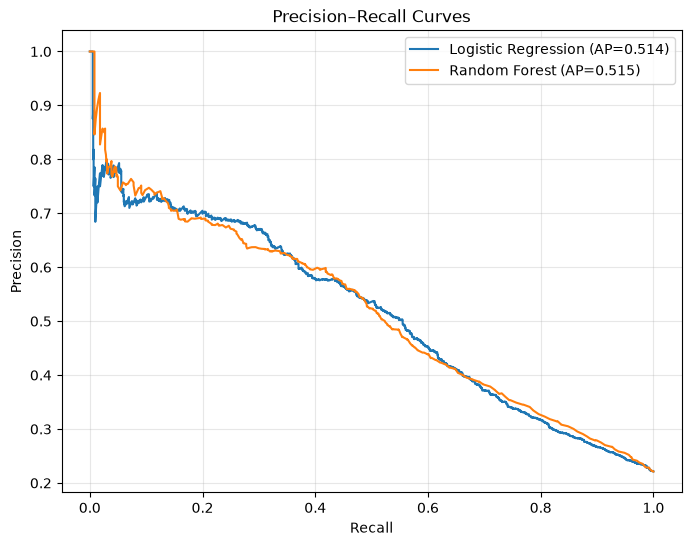

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, average_precision_score

# Calculating precision and recall across classification thresholds
lr_precision, lr_recall, _ = precision_recall_curve(y_test, logistic_prob)
rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_prob)

# Comparing the models' precision–recall trade-offs
plt.figure(figsize=(8, 6))
plt.plot(
    lr_recall, lr_precision,
    label=f"Logistic Regression (AP={average_precision_score(y_test, logistic_prob):.3f})"
)
plt.plot(
    rf_recall, rf_precision,
    label=f"Random Forest (AP={average_precision_score(y_test, rf_prob):.3f})"
)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

I have already inspected several test-set metrics and curves. That makes the test set less strictly untouched than intended. I can still report these exploratory results, but the final threshold is selected using training data only, and the limitation is documented. 
though we know inspecting test results does not change the data, but using those results to make modelling decisions can introduce selection bias. I willl use training-set out-of-fold probabilities for threshold selection and reserve the test set for the final evaluation as far as possible.

In [14]:
from sklearn.model_selection import cross_val_predict

# Generating out-of-fold default probabilities for Logistic Regression
lr_oof_prob = cross_val_predict(
    logistic_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Generating out-of-fold default probabilities for Random Forest
rf_oof_prob = cross_val_predict(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Checking the number of probabilities generated for each model
print("Logistic Regression:", len(lr_oof_prob))
print("Random Forest:", len(rf_oof_prob))

Logistic Regression: 23972
Random Forest: 23972


In [15]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Testing lower thresholds to measure the trade-off in default detection
thresholds = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50]

for name, probabilities in [
    ("Logistic Regression", lr_oof_prob),
    ("Random Forest", rf_oof_prob)
]:
    print(f"\n{name}")
    for threshold in thresholds:
        predictions = (probabilities >= threshold).astype(int)
        precision = precision_score(y_train, predictions, zero_division=0)
        recall = recall_score(y_train, predictions, zero_division=0)
        f1 = f1_score(y_train, predictions, zero_division=0)

        print(
            f"Threshold={threshold:.2f} | "
            f"Precision={precision:.3f} | "
            f"Recall={recall:.3f} | F1={f1:.3f}"
        )


Logistic Regression
Threshold=0.20 | Precision=0.438 | Recall=0.646 | F1=0.522
Threshold=0.25 | Precision=0.460 | Recall=0.613 | F1=0.526
Threshold=0.30 | Precision=0.509 | Recall=0.559 | F1=0.533
Threshold=0.35 | Precision=0.539 | Recall=0.514 | F1=0.526
Threshold=0.40 | Precision=0.570 | Recall=0.461 | F1=0.510
Threshold=0.45 | Precision=0.621 | Recall=0.365 | F1=0.460
Threshold=0.50 | Precision=0.649 | Recall=0.294 | F1=0.404

Random Forest
Threshold=0.20 | Precision=0.384 | Recall=0.709 | F1=0.498
Threshold=0.25 | Precision=0.444 | Recall=0.638 | F1=0.523
Threshold=0.30 | Precision=0.495 | Recall=0.580 | F1=0.534
Threshold=0.35 | Precision=0.536 | Recall=0.522 | F1=0.529
Threshold=0.40 | Precision=0.570 | Recall=0.471 | F1=0.516
Threshold=0.45 | Precision=0.605 | Recall=0.426 | F1=0.500
Threshold=0.50 | Precision=0.632 | Recall=0.373 | F1=0.469


Threshold comparison
Metric at threshold 0.30	Logistic Regression	Random Forest
Precision	0.509	0.495
Recall	0.559	0.580
F1-score	0.533	0.534

Interpretation
- Random Forest catches slightly more defaulters.
- Logistic Regression produces slightly fewer false alarms among predicted defaulters.
- Their F1-scores are nearly identical at this threshold.
- At threshold 0.20, Random Forest reaches 70.9% recall, but precision falls to 38.4%.
These are training-set out-of-fold results, not final test results. Also, the best threshold depends on the business objective; the highest F1-score is not automatically the best operational choice.

In [16]:
# Setting the provisional classification threshold from cross-validation results
selected_threshold = 0.30

# Recording the chosen threshold for consistent model evaluation
print("Provisional threshold:", selected_threshold)

Provisional threshold: 0.3


In [17]:
from sklearn.metrics import classification_report, roc_auc_score

# Converting test probabilities into class predictions at the selected threshold
lr_test_pred_030 = (logistic_prob >= selected_threshold).astype(int)
rf_test_pred_030 = (rf_prob >= selected_threshold).astype(int)

# Evaluating Logistic Regression at the provisional threshold
print("Logistic Regression — threshold 0.30")
print(classification_report(y_test, lr_test_pred_030, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, logistic_prob), 4))

# Evaluating Random Forest at the provisional threshold
print("\nRandom Forest — threshold 0.30")
print(classification_report(y_test, rf_test_pred_030, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, rf_prob), 4))

Logistic Regression — threshold 0.30
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      4667
           1       0.51      0.54      0.53      1326

    accuracy                           0.78      5993
   macro avg       0.69      0.70      0.69      5993
weighted avg       0.79      0.78      0.78      5993

ROC-AUC: 0.7515

Random Forest — threshold 0.30
              precision    recall  f1-score   support

           0       0.87      0.83      0.85      4667
           1       0.48      0.55      0.51      1326

    accuracy                           0.77      5993
   macro avg       0.67      0.69      0.68      5993
weighted avg       0.78      0.77      0.77      5993

ROC-AUC: 0.7581



### Threshold Selection and Final Evaluation

I compared Logistic Regression and Random Forest using out-of-fold probabilities generated through five-fold cross-validation on the training set. I tested thresholds from 0.20 to 0.50 and selected 0.30 as a provisional threshold because it provided the highest F1-score among the tested thresholds for both models.

At a threshold of 0.30, the test-set results were:

| Metric | Logistic Regression | Random Forest |
|---|---:|---:|
| Accuracy | 0.78 | 0.77 |
| Default precision | 0.51 | 0.48 |
| Default recall | 0.54 | 0.55 |
| Default F1-score | 0.53 | 0.51 |
| ROC-AUC | 0.7515 | 0.7581 |

Lowering the threshold from 0.50 to 0.30 increased default recall for both models, but also reduced precision and accuracy. Logistic Regression achieved a slightly higher default F1-score and precision, while Random Forest achieved marginally higher recall and ROC-AUC.

Based on these results, I consider Logistic Regression the provisional preferred model at the 0.30 threshold because it provides a better balance between precision and recall. Random Forest remains a useful comparison model.

**Limitation:** I inspected test-set results before selecting the threshold, so the test set was not completely untouched during model development. I selected the threshold using training-set out-of-fold probabilities, but the earlier test-set inspection may still introduce selection bias. I will report this limitation when presenting the final results.

These findings apply to the historical Taiwanese credit-card dataset used in this project and should not be interpreted as evidence of performance on current borrowers or other populations.


In [18]:
# Counting classification outcomes at the selected threshold
for name, predictions in [
    ("Logistic Regression", lr_test_pred_030),
    ("Random Forest", rf_test_pred_030)
]:
    print(f"\n{name}")
    print(confusion_matrix(y_test, predictions))


Logistic Regression
[[3965  702]
 [ 604  722]]

Random Forest
[[3864  803]
 [ 595  731]]



### Confusion Matrix Analysis at Threshold 0.30

Here I compared the confusion matrices of both models at the selected threshold of 0.30.

Logistic Regression correctly identified 722 defaulters and missed 604. It incorrectly flagged 702 non-defaulters as defaulters. Random Forest correctly identified 731 defaulters and missed 595, but it incorrectly flagged 803 non-defaulters.

Random Forest detected 9 additional defaulters compared with Logistic Regression, while Logistic Regression produced 101 fewer false positives. This reinforces the trade-off between detecting more defaulters and avoiding unnecessary false alarms.

Based on the precision, recall, F1-score, and confusion matrices, I retain Logistic Regression as my provisional preferred model at threshold 0.30. Random Forest remains a useful challenger because it achieves slightly higher recall and ROC-AUC.



## Phase 3 Summary and Conclusion

I established a DummyClassifier baseline, trained Logistic Regression as the primary model, and evaluated Random Forest as a challenger. I used stratified train/test splitting and five-fold cross-validation to compare model performance.

The DummyClassifier achieved 77.87% accuracy but detected no defaulters. Both predictive models improved on this baseline, with ROC-AUC scores above 0.75.

I selected 0.30 as a provisional classification threshold based on training-set out-of-fold results. At this threshold, Logistic Regression achieved a default precision of approximately 0.51, recall of 0.54, and F1-score of 0.53 on the test set. Random Forest achieved approximately 0.48 precision, 0.55 recall, and 0.51 F1-score.

I retain Logistic Regression as the provisional preferred model because it offers a slightly better balance between precision and recall at the selected threshold. Random Forest remains a competitive alternative with marginally higher ROC-AUC and recall.

### Limitations

- The dataset represents Taiwanese credit-card clients and historical data from 2005; results may not generalize to current borrowers or other populations.
- The test set was inspected during exploratory evaluation before threshold selection, introducing a potential selection-bias limitation.
- The threshold of 0.30 is an analytical choice, not a validated lending policy.
- The models have not been established as suitable for real-world credit decisions.
- Further work would be needed to assess probability calibration, fairness, and performance on genuinely unseen data.
